# Energy is in the field: from Maxwell to lumped circuits you can solve on paper

Feynman's point in *Lectures* Vol. II (Ch. 22, 23, 27): circuit theory is an **approximation**
to electromagnetism, and the energy of a circuit lives in the **fields**, not in the wires. These
are this repo's own derivations of those ideas. For his wording, read the free online edition at
feynmanlectures.caltech.edu.

1. Field energy: ½CV² and ½LI² are integrals of the field energy density
2. Poynting: a resistor's heat flows in from *outside* the wire
3. A capacitor at high frequency becomes a cavity: the EM version of the particle-in-a-box wall
4. The lumped-circuit assumptions table: what each one drops from Maxwell, and when it fails
5. Deriving circuits on paper: nodal analysis that SymPy checks
6. Practice: use the functions you already have

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
import numpy as np, pandas as pd, sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
sp.init_printing(use_unicode=True)
pd.set_option("display.max_colwidth", 80)
from dgs import field_circuits as F
from dgs.field_circuits import Circuit, s

## 1. The energy is in the field

The energy density is u = ε₀E²/2 + B²/(2μ₀). Integrate it over the gap of a capacitor or the
inside of a solenoid, and you get exactly the circuit formulas.

In [2]:
for label, fn, circ in [("capacitor", F.capacitor_field_energy, "C"), ("solenoid", F.solenoid_field_energy, "L")]:
    res = fn()
    display(Markdown(f"**{label}**: u = ${sp.latex(res['u'])}$,  field integral = ${sp.latex(res['U_field'])}$, "
                     f"with {circ} = ${sp.latex(res[circ])}$ this is ${sp.latex(res['U_circuit'])}$.  Match: **{res['match']}**"))

**capacitor**: u = $\frac{V^{2} \epsilon_{0}}{2 d^{2}}$,  field integral = $\frac{A V^{2} \epsilon_{0}}{2 d}$, with C = $\frac{A \epsilon_{0}}{d}$ this is $\frac{A V^{2} \epsilon_{0}}{2 d}$.  Match: **True**

**solenoid**: u = $\frac{I^{2} \mu_{0} n^{2}}{2}$,  field integral = $\frac{A I^{2} \ell \mu_{0} n^{2}}{2}$, with L = $A \ell \mu_{0} n^{2}$ this is $\frac{A I^{2} \ell \mu_{0} n^{2}}{2}$.  Match: **True**

## 2. Poynting: heat comes in from outside the wire

Inside a resistive wire, E points along the current, and B circles the wire. S = E × B / μ₀
then points **radially inward**. Its flux through the wire's surface is exactly I²R. The battery's
energy travels through the space around the wires and enters the resistor from the side.

E = $\frac{I R}{\ell}$, B = $\frac{I \mu_{0}}{2 \pi a}$, |S| = $\frac{I^{2} R}{2 \pi a \ell}$, S x (2 pi a ell) = $I^{2} R$ -> I²R: **True**

Charging capacitor: inflow through the open side $\pi a^{2} d \epsilon_{0} E{\left(t \right)} \frac{d}{d t} E{\left(t \right)}$ = d/dt(stored) $\pi a^{2} d \epsilon_{0} E{\left(t \right)} \frac{d}{d t} E{\left(t \right)}$: **True**

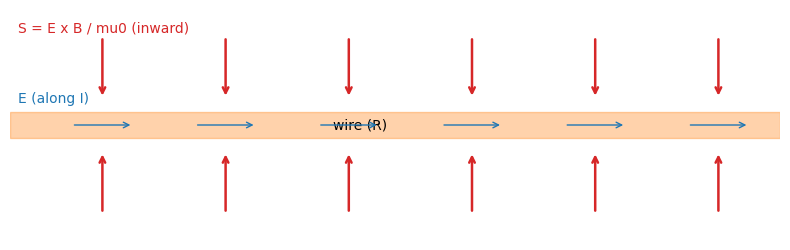

In [3]:
p = F.wire_poynting()
display(Markdown(f"E = ${sp.latex(p['E'])}$, B = ${sp.latex(p['B'])}$, |S| = ${sp.latex(p['S'])}$, "
                 f"S x (2 pi a ell) = ${sp.latex(p['P_in'])}$ -> I²R: **{p['match']}**"))
q = F.charging_capacitor_poynting()
display(Markdown(f"Charging capacitor: inflow through the open side ${sp.latex(q['P_in'])}$ = "
                 f"d/dt(stored) ${sp.latex(q['dU_dt'])}$: **{q['match']}**"))

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.add_patch(plt.Rectangle((0, -0.15), 10, 0.3, color="C1", alpha=0.35)); ax.text(4.2, -0.05, "wire (R)")
for x in np.arange(0.8, 10, 1.6):
    ax.annotate("", (x + 0.8, 0), (x, 0), arrowprops=dict(arrowstyle="->", color="C0"))
    for y0, dy in [(1.0, -0.7), (-1.0, 0.7)]:
        ax.annotate("", (x + 0.4, y0 + dy), (x + 0.4, y0), arrowprops=dict(arrowstyle="->", color="C3", lw=1.8))
ax.text(0.1, 0.25, "E (along I)", color="C0"); ax.text(0.1, 1.05, "S = E x B / mu0 (inward)", color="C3")
ax.set_xlim(0, 10); ax.set_ylim(-1.3, 1.3); ax.axis("off"); plt.tight_layout(); plt.show()

## 3. Capacitor → cavity: the EM version of the "wall"

At low frequency, the field between two circular plates is uniform: that's the lumped capacitor.
Raise ω, and the changing E makes a B, which makes a correction to E, and so on. The full sum is
E(r) = E₀ J₀(ωr/c). Where J₀ first hits zero (ωa/c = 2.405), you can close the edge with a metal
wall and nothing changes. The capacitor has become a **resonant cavity**.

This is the reading quiz from last time, in electromagnetic form. At a perfect conductor the
tangential E must be **zero**, just as ψ = 0 inside an infinite wall. So cavity modes are standing
waves, like particle-in-a-box states.

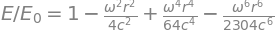

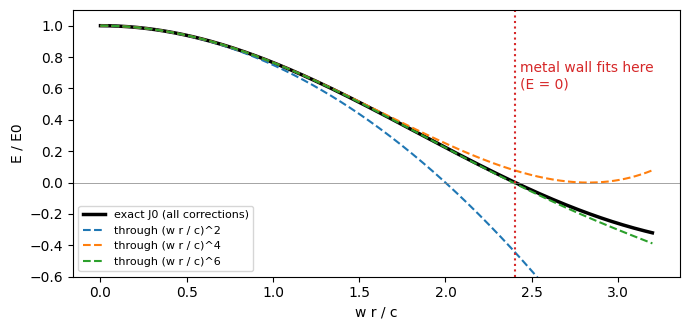

,plate radius,lowest cavity resonance
0,100 mm,1.147 GHz
1,10 mm,11.47 GHz
2,1 mm,114.7 GHz
3,0.115 mm,997.8 GHz


,,particle in a box,electromagnetic cavity
0,wall condition,psi = 0 in an infinite wall,tangential E = 0 at a perfect conductor
1,allowed modes,sin(n pi x / L),sin(n pi x / L) for a 1-D cavity
2,frequencies,E_n ~ n^2 (massive particle),f_n = n c / 2L (photon)
3,forbidden but finite,psi decays exponentially,evanescent field below waveguide cutoff


In [4]:
display(sp.Eq(sp.Symbol("E/E_0"), F.capacitor_field_series(3)))
xs = np.linspace(0, 3.2, 300)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(xs, [float(sp.besselj(0, x)) for x in xs], "k", lw=2.5, label="exact J0 (all corrections)")
xx = sp.Symbol("xx")
for k in (1, 2, 3):
    ser = F.capacitor_field_series(k).subs({F.w * F.r / F.c: xx}).subs({F.r: xx * F.c / F.w})
    f = sp.lambdify(xx, sp.simplify(ser))
    ax.plot(xs, f(xs), "--", label=f"through (w r / c)^{2 * k}")
ax.axhline(0, c="gray", lw=0.5); ax.axvline(F.first_bessel_zero(), c="C3", ls=":")
ax.text(F.first_bessel_zero() + 0.03, 0.6, "metal wall fits here\n(E = 0)", color="C3")
ax.set(xlabel="w r / c", ylabel="E / E0", ylim=(-0.6, 1.1)); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
display(pd.DataFrame([(f"{a*1e3:g} mm", f"{F.cavity_resonance_hz(a)/1e9:.4g} GHz") for a in (100e-3, 10e-3, 1e-3, 0.115e-3)],
                     columns=["plate radius", "lowest cavity resonance"]))
display(pd.DataFrame([("wall condition", "psi = 0 in an infinite wall", "tangential E = 0 at a perfect conductor"),
                      ("allowed modes", "sin(n pi x / L)", "sin(n pi x / L) for a 1-D cavity"),
                      ("frequencies", "E_n ~ n^2 (massive particle)", "f_n = n c / 2L (photon)"),
                      ("forbidden but finite", "psi decays exponentially", "evanescent field below waveguide cutoff")],
                     columns=["", "particle in a box", "electromagnetic cavity"]))

## 4. The lumped-circuit assumptions table

In [5]:
display(pd.DataFrame(F.LUMPED_ASSUMPTIONS))
from dgs import lc_oscillator as O
display(pd.DataFrame([(f"{f:.0e} Hz", f"{O.lumped_ok(f, 0.05)['size_over_lambda']:.3g}", O.lumped_ok(f, 0.05)["lumped_ok"])
                      for f in (60, 1e6, 100e6, 1e9, 10e9)], columns=["frequency", "5 cm board / lambda", "lumped OK?"]))

,assumption,maxwell,dropped,gives,fails_when
0,No changing magnetic flux outside the elements,curl E = -dB/dt,dB/dt outside inductors,KVL: voltages around a loop add to zero; a unique V between two nodes,"loops pick up flux: ground loops, transformer coupling, crosstalk"
1,No charge piling up inside wires or nodes,div J = -d(rho)/dt,d(rho)/dt in the wires,KCL: currents into a node add to zero,"parasitic capacitance to ground matters (fast edges, long traces)"
2,Each element is much smaller than a wavelength,"wave equation, speed c",propagation delay,every point of a wire has the same V at the same instant,"size > lambda/10: GHz boards, THz, long cables -> transmission lines"
3,Each element's field is isolated inside it,fields of different parts don't overlap,mutual coupling,"each element described by one law (V = IR, I = C dV/dt, V = L dI/dt)",elements couple: add mutual inductance M or a parasitic C to the model
4,No radiation,Poynting flux to infinity,radiated power,"all energy stays in R (heat), C (E field) and L (B field)",the circuit is an antenna: size ~ lambda/4


,frequency,5 cm board / lambda,lumped OK?
0,6e+01 Hz,1e-08,True
1,1e+06 Hz,0.000167,True
2,1e+08 Hz,0.0167,True
3,1e+09 Hz,0.167,False
4,1e+10 Hz,1.67,False


## 5. Deriving circuits on paper, with SymPy as the checker

The same five steps work for any reasonably sized circuit:
1. Label the nodes and pick ground.
2. List the unknowns: node voltages, plus one current per voltage source.
3. Write KCL at each node: the sum of currents *leaving* is 0. Use impedances Z_R = R,
   Z_C = 1/(sC), Z_L = sL, so each current is (V_a − V_b)/Z.
4. Solve A x = b.
5. Check units and the limits: s → 0 (C open, L short) and s → ∞ (C short, L open).

Do it by hand first, then run the cell to compare.

### voltage divider

1. Label every node; node 0 is ground: in, out
2. Unknowns: V_in, V_out, I_Vs
3. KCL (currents leaving each node = 0), and source constraints:
     I_Vs + (V_in - V_out)/R_1 = 0
     V_out/R_2 - (V_in - V_out)/R_1 = 0
     V_in = V_s
4. Write as A x = b and solve (substitution, Cramer, or row reduction).
     I_Vs = -V_s/(R_1 + R_2)
     V_in = V_s
     V_out = R_2*V_s/(R_1 + R_2)
5. Check: units, s -> 0 (capacitors open, inductors short), s -> oo.


  DC (s -> 0): R_2/(R_1 + R_2)    s -> oo: R_2/(R_1 + R_2) 



### RC low-pass

1. Label every node; node 0 is ground: in, out
2. Unknowns: V_in, V_out, I_Vs
3. KCL (currents leaving each node = 0), and source constraints:
     I_Vs + (V_in - V_out)/R = 0
     C*V_out*s - (V_in - V_out)/R = 0
     V_in = V_s
4. Write as A x = b and solve (substitution, Cramer, or row reduction).
     I_Vs = -C*V_s*s/(C*R*s + 1)
     V_in = V_s
     V_out = V_s/(C*R*s + 1)
5. Check: units, s -> 0 (capacitors open, inductors short), s -> oo.


  DC (s -> 0): 1    s -> oo: 0 



### series RLC band-pass

1. Label every node; node 0 is ground: in, a, out
2. Unknowns: V_in, V_a, V_out, I_Vs
3. KCL (currents leaving each node = 0), and source constraints:
     I_Vs + (-V_a + V_in)/(L*s) = 0
     C*s*(V_a - V_out) - (-V_a + V_in)/(L*s) = 0
     -C*s*(V_a - V_out) + V_out/R = 0
     V_in = V_s
4. Write as A x = b and solve (substitution, Cramer, or row reduction).
     I_Vs = -C*V_s*s/(C*L*s**2 + C*R*s + 1)
     V_a = V_s*(C*R*s + 1)/(C*L*s**2 + C*R*s + 1)
     V_in = V_s
     V_out = C*R*V_s*s/(C*L*s**2 + C*R*s + 1)
5. Check: units, s -> 0 (capacitors open, inductors short), s -> oo.


  DC (s -> 0): 0    s -> oo: 0 



### Wheatstone bridge (node a)

1. Label every node; node 0 is ground: top, a, b
2. Unknowns: V_top, V_a, V_b, I_Vs
3. KCL (currents leaving each node = 0), and source constraints:
     I_Vs + (-V_b + V_top)/R_3 + (-V_a + V_top)/R_1 = 0
     V_a/R_2 - (-V_a + V_top)/R_1 + (V_a - V_b)/R = 0
     V_b/R_4 - (-V_b + V_top)/R_3 - (V_a - V_b)/R = 0
     V_top = V_s
4. Write as A x = b and solve (substitution, Cramer, or row reduction).
     I_Vs = V_s*(-R*R_1 - R*R_2 - R*R_3 - R*R_4 - R_1*R_2 - R_1*R_4 - R_2*R_3 - R_3*R_4)/(R*R_1*R_3 + R*R_1*R_4 + R*R_2*R_3 + R*R_2*R_4 + R_1*R_2*R_3 + R_1*R_2*R_4 + R_1*R_3*R_4 + R_2*R_3*R_4)
     V_a = R_2*V_s*(R*R_3 + R*R_4 + R_1*R_4 + R_3*R_4)/(R*R_1*R_3 + R*R_1*R_4 + R*R_2*R_3 + R*R_2*R_4 + R_1*R_2*R_3 + R_1*R_2*R_4 + R_1*R_3*R_4 + R_2*R_3*R_4)
     V_b = R_4*V_s*(R*R_1 + R*R_2 + R_1*R_2 + R_2*R_3)/(R*R_1*R_3 + R*R_1*R_4 + R*R_2*R_3 + R*R_2*R_4 + R_1*R_2*R_3 + R_1*R_2*R_4 + R_1*R_3*R_4 + R_2*R_3*R_4)
     V_top = V_s
5. Check: units, s -> 0 (capacitors open, inductors short), s -> oo.

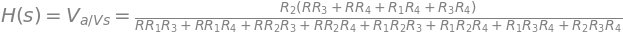

  DC (s -> 0): R_2*(R*R_3 + R*R_4 + R_1*R_4 + R_3*R_4)/(R*R_1*R_3 + R*R_1*R_4 + R*R_2*R_3 + R*R_2*R_4 + R_1*R_2*R_3 + R_1*R_2*R_4 + R_1*R_3*R_4 + R_2*R_3*R_4)    s -> oo: R_2*(R*R_3 + R*R_4 + R_1*R_4 + R_3*R_4)/(R*R_1*R_3 + R*R_1*R_4 + R*R_2*R_3 + R*R_2*R_4 + R_1*R_2*R_3 + R_1*R_2*R_4 + R_1*R_3*R_4 + R_2*R_3*R_4) 



In [6]:
for name, ckt, out, src in F.example_circuits():
    display(Markdown(f"### {name}"))
    print(ckt.paper())
    H = ckt.transfer(out, src)
    display(sp.Eq(sp.Symbol(f"H(s) = V_{out}/V_s"), H))
    print("  DC (s -> 0):", sp.limit(H, s, 0), "   s -> oo:", sp.limit(H, s, sp.oo), "\n")

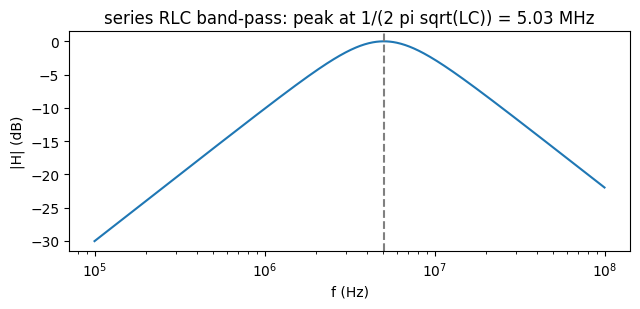

In [7]:
# Bode plot of the band-pass, numbers in
Rv, Cv, Lv = 50.0, 1e-9, 1e-6
H = F.example_circuits()[2][1].transfer("out", "Vs")
Hn = sp.lambdify(s, H.subs({sp.Symbol("R", positive=True): Rv, sp.Symbol("C", positive=True): Cv, sp.Symbol("L", positive=True): Lv}))
f = np.logspace(5, 8, 600)
plt.figure(figsize=(6.5, 3.2)); plt.semilogx(f, 20 * np.log10(np.abs(Hn(2j * np.pi * f))))
plt.axvline(1 / (2 * np.pi * np.sqrt(Lv * Cv)), ls="--", c="gray")
plt.xlabel("f (Hz)"); plt.ylabel("|H| (dB)"); plt.title("series RLC band-pass: peak at 1/(2 pi sqrt(LC)) = 5.03 MHz")
plt.tight_layout(); plt.show()

**Your turn:** build your own circuit below (EEE 117 homework style). Work it on paper,
then run the cell to check. Here it's a current source feeding a T-network.

In [8]:
mine = (Circuit().I("Is", "0", "a", 2)          # 2 A into node a
        .R("R1", "a", "0", 5).R("R2", "a", "b", 10).R("R3", "b", "0", 10))
print(mine.paper())
A, b = mine.matrix(); display(A, b)

1. Label every node; node 0 is ground: a, b
2. Unknowns: V_a, V_b
3. KCL (currents leaving each node = 0), and source constraints:
     3*V_a/10 - V_b/10 - 2 = 0
     -V_a/10 + V_b/5 = 0
4. Write as A x = b and solve (substitution, Cramer, or row reduction).
     V_a = 8
     V_b = 4
5. Check: units, s -> 0 (capacitors open, inductors short), s -> oo.


⎡3/10   -1/10⎤
⎢            ⎥
⎣-1/10   1/5 ⎦

⎡2⎤
⎢ ⎥
⎣0⎦

## 6. Use the functions you already have

One call from each toolkit built this term. Change the numbers and rerun; that's the practice.

In [9]:
from dgs import (one_d_quantum as Q, laser_safety as LS, cryo_readout as CR, nv_diamond as NV,
                 engineering_economics as EE, queueing as QU, phys106_frq as FRQ,
                 digital_logic_power as DL, modern_physics_vocab as VOC)
drill = [
    ("PHYS 106 Ch 40", "Q.box_energy(1, 0.5)", "electron, 0.5 nm box (eV)"),
    ("PHYS 106 Ch 40", "Q.tunneling_probability(3.0, 5.0, 0.4)", "3 eV electron, 5 eV x 0.4 nm barrier"),
    ("PHYS 106 FRQ", "FRQ.grade('photoelectric', 'b', '1.7 eV')['feedback']", "grade your own answer"),
    ("PHYS 106 vocab", "VOC.lookup('work function')[0].english", "plain-English definition"),
    ("laser safety", "f'{LS.photon_rate(5e-3, 532):.3g} photons/s'", "5 mW green pointer"),
    ("qubit fridge", "CR.excited_population(5e9, 0.010)", "5 GHz qubit at 10 mK"),
    ("NV diamond", "[f'{x/1e9:.4f} GHz' for x in NV.odmr_frequencies([0, 0, 1e-3])]", "ODMR lines, 1 mT along the NV axis"),
    ("ENGR 140", "round(EE.npv([-1000, 400, 400, 400], 0.08), 2)", "is a $1000 tool worth it at 8%?"),
    ("queues / sim", "round(QU.erlang_c(lam=4, mu=1, c=5), 4)", "P(wait) with 5 servers"),
    ("logic / power", "DL.kmap([0, 2, 5, 7], list('ABC'))[3]", "minimize a K-map"),
    ("logic / power", "DL.energy_power_time(P=60, t=3600)", "60 W bulb for an hour"),
    ("this notebook", "F.cavity_resonance_hz(0.01) / 1e9", "1 cm pillbox cavity (GHz)"),
]
rows = [(topic, call, desc, str(eval(call))) for topic, call, desc in drill]
display(pd.DataFrame(rows, columns=["topic", "call", "what it answers", "result"]))

,topic,call,what it answers,result
0,PHYS 106 Ch 40,"Q.box_energy(1, 0.5)","electron, 0.5 nm box (eV)",1.5041206495515955
1,PHYS 106 Ch 40,"Q.tunneling_probability(3.0, 5.0, 0.4)","3 eV electron, 5 eV x 0.4 nm barrier",0.003039075100052144
2,PHYS 106 FRQ,"FRQ.grade('photoelectric', 'b', '1.7 eV')['feedback']",grade your own answer,Correct.
3,PHYS 106 vocab,VOC.lookup('work function')[0].english,plain-English definition,Minimum energy needed to free an electron from a metal.
4,laser safety,"f'{LS.photon_rate(5e-3, 532):.3g} photons/s'",5 mW green pointer,1.34e+16 photons/s
5,qubit fridge,"CR.excited_population(5e9, 0.010)",5 GHz qubit at 10 mK,3.789449114160926e-11
6,NV diamond,"[f'{x/1e9:.4f} GHz' for x in NV.odmr_frequencies([0, 0, 1e-3])]","ODMR lines, 1 mT along the NV axis","['2.8420 GHz', '2.8980 GHz']"
7,ENGR 140,"round(EE.npv([-1000, 400, 400, 400], 0.08), 2)",is a $1000 tool worth it at 8%?,30.84
8,queues / sim,"round(QU.erlang_c(lam=4, mu=1, c=5), 4)",P(wait) with 5 servers,0.5541
9,logic / power,"DL.kmap([0, 2, 5, 7], list('ABC'))[3]",minimize a K-map,(A & C) | (~A & ~C)
